In [191]:
import numpy as np 
import matplotlib.pyplot as plt
from hcipy import *
import os
import sys

sys.path.append(os.path.abspath(os.path.join(os.path.dirname('adc_sims'), '..')))

from adcFitter_onsky import AdcFitter

In [192]:
folder_path = '/Users/Katie/Documents/MagAO-X/Data/ADC/nov16th_working_onsky/2024-11-17_091510_piPup_ADC_open/camsci1'

# Get all image file paths in the folder
image_files = [os.path.join(folder_path, file) for file in os.listdir(folder_path) if file.startswith("camsci1_") and file.endswith('.fits')]
image_files = sorted(image_files, key=lambda x: int(x.split('_')[-1].split('.')[0]))


# Load all images into a list
images = [read_fits(img_path) for img_path in image_files]

print(f"Loaded {len(images)} images.")


Loaded 220 images.


In [193]:
#system params
wavelength = 764E-9
bw = 120E-9
grating_angle = 28
grating_freq = 47

ADC = AdcFitter(wavelength=wavelength,grating_freq=grating_freq,grating_angle=grating_angle)

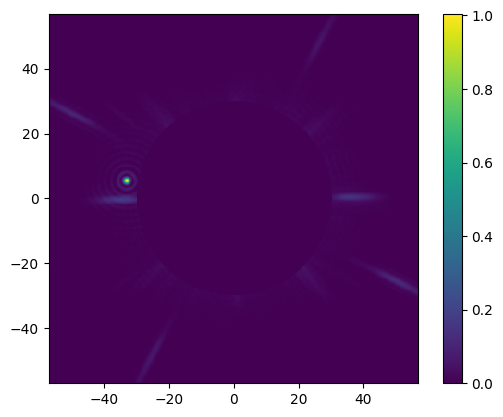

In [194]:
#now going through and turning each image into an hcipy field that has the same dimensions as the images taken with jupyter (lam/d at Ha)
difference_cube = read_field('/Users/Katie/Documents/MagAO-X/Data/ADC/nov20th_onsky_newaxis/orientations.fits')
igrid = difference_cube.grid


extent = np.array(igrid.separated_coords).max()
grid = make_uniform_grid([512,512],extent)
fields = []
cropped = []

for im in images:
    im = im.ravel()
    im = Field(im,grid)
    fields.append(im)
    cropped.append(ADC.crop_image(ADC.filter_image(im)))

imshow_field(cropped[10])
plt.colorbar()
plt.show()

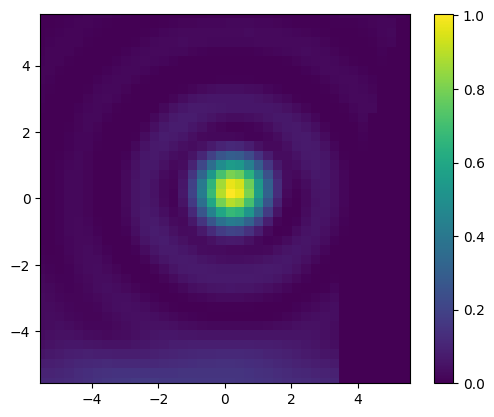

fwhm: 6 pixels


In [195]:
img = cropped[0]

peak = np.argmax(img)
window_center = img.grid.points[peak]

pup = ADC.window_field(img,window_center,40,40)
slice = pup.shaped[:,20]

plt.figure()
imshow_field(pup)
plt.colorbar()
plt.show()

#find the max. split it into two. find the point closest to 0.5 in both halves.
split = np.argmax(slice)
left = np.abs(slice[0:split] - 0.5)
right = np.abs(slice[split:40] - 0.5)
lpoint = np.argmin(left)
rpoint = np.argmin(right) + split
fwhm = rpoint - lpoint

print(f'fwhm: {fwhm} pixels')

# plt.figure()
# plt.plot(slice,'o-')
# plt.vlines(split,0,1,'red')
# plt.hlines(0.5,0,40,'black')
# plt.plot(lpoint,slice[lpoint],'go')
# plt.plot(rpoint,slice[rpoint],'go')
# plt.show()

5.721241772279496


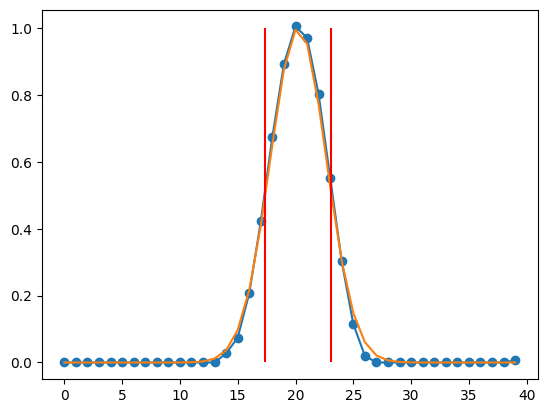

In [196]:
#start from the peak value and scan through the gradient outwards, find where the gradient switches direction. truncate the data there.
from scipy.optimize import curve_fit


def gauss(x,mu,sigma2):
    return np.exp(-(x-mu)**2 / (2 * sigma2) )

def isolate_gaussian(data):
    mid = np.argmax(data)
    first_derivative = np.gradient(data) 

    valley_indices = np.where((first_derivative[:-1] < 0) & (first_derivative[1:] > 0))[0] + 1

    left_valley = valley_indices[valley_indices < mid][-1] if any(valley_indices < mid) else None
    right_valley = valley_indices[valley_indices > mid][0] if any(valley_indices > mid) else None

    if left_valley is not None:
        data[0:left_valley] = 0
        #right_valley -= left_valley

    if right_valley is not None:
        data[right_valley:len(data)-1] = 0
        #print(right_valley)

    return data

def fwhm(data):
    isolated = isolate_gaussian(data)
    x = np.arange(40)
    popt = curve_fit(gauss,x,isolated,p0 = [20,4])

    mu = popt[0][0]
    sigma = popt[0][1]
    fwhm = 2 * np.sqrt(2 * np.log(2)) * np.sqrt(sigma)
    return fwhm, mu, sigma
    

width, mean, sd = fwhm(slice)
x = np.arange(40)
print(width)

s = isolate_gaussian(slice)

plt.figure()
plt.plot(s,'-o')
plt.plot(x,gauss(x,mean,sd),'-')
plt.vlines(mean - width/2,0,1,'red')
plt.vlines(mean + width/2,0,1,'red')
plt.show()

In [197]:
#now to measure a response based on fitted FWHM
#fit a FWHM to each of the images
widths = []

for img in cropped:
    peak = np.argmax(img)
    window_center = img.grid.points[peak]

    pup = ADC.window_field(img,window_center,40,40)
    slice_column = np.array(np.unravel_index(np.argmax(pup),(40,40)))[0]
    slice = pup.shaped[:,slice_column]

    width, mean, sd = fwhm(slice)
    widths.append(width)

widths = np.array(widths)

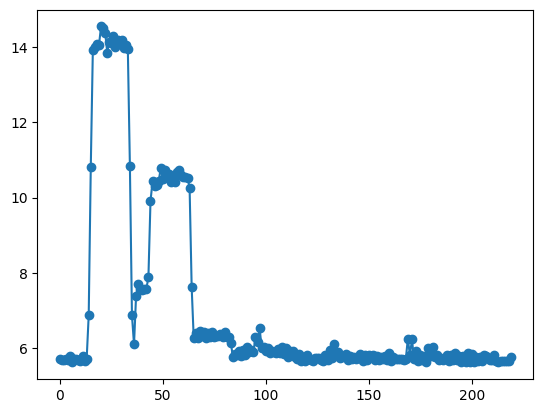

In [198]:
#each of these y's are a step in the correction
y1 = np.mean(widths[0:12]) #0
y2 = np.mean(widths[15:35]) #5
y3 = np.mean(widths[37:43]) #2.12
y4 = np.mean(widths[45:64]) #3.72
y5 = np.mean(widths[66:80]) #0.97
y6 = np.mean(widths[86:93]) #-0.54
y7 = np.mean(widths[190:220]) #0.086,0.063
ys = np.array([y1,y2,y3,y4,y5,y6,y7])

#delineating between the different steps was done by plotting and approximating by eye
plt.plot(widths,'-o')
# plt.plot(12,y1,'o')
# plt.plot(15,y2,'o')
# plt.plot(35,y2,'o')
# plt.plot(37,y3,'o')
# plt.plot(43,y3,'o')
# plt.plot(45,y4,'o')
# plt.plot(64,y4,'o')
# plt.plot(66,y5,'o')
# plt.plot(80,y5,'o')
# plt.plot(86,y6,'o')
# plt.plot(93,y6,'o')
# plt.hlines(y6,190,220,colors='red')

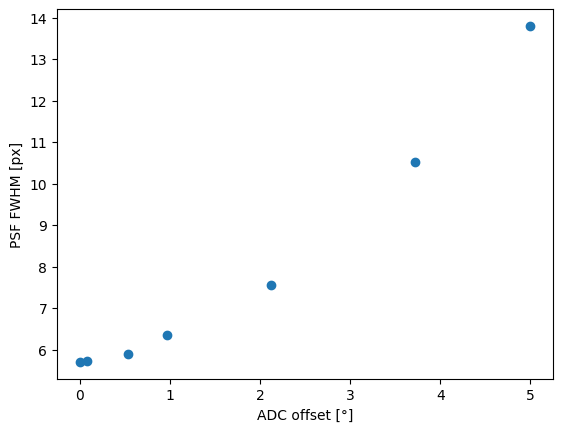

In [199]:
#now plotting ADC offset versus FWHM
adc_angles = np.array([0,5,2.12,3.72,0.97,0.54,0.086]) #pulled from the records, absolute value taken because sign doesn't matter
plt.scatter(adc_angles,ys)
plt.xlabel('ADC offset [°]')
plt.ylabel('PSF FWHM [px]')
plt.show()

#lol that's a parabola if i've ever seen one

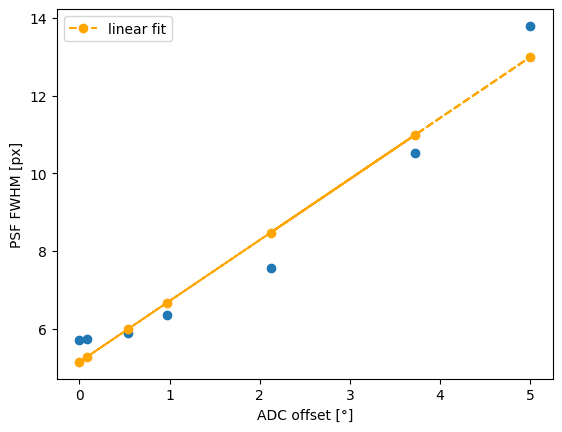

1.571727546493059


In [203]:
m,b = np.polyfit(adc_angles,ys,deg=1)

plt.figure()
plt.scatter(adc_angles,ys)
plt.plot(adc_angles,m*adc_angles+b,'--o',label='linear fit',color='orange')
plt.xlabel('ADC offset [°]')
plt.ylabel('PSF FWHM [px]')
plt.legend()
plt.show()

print(m)

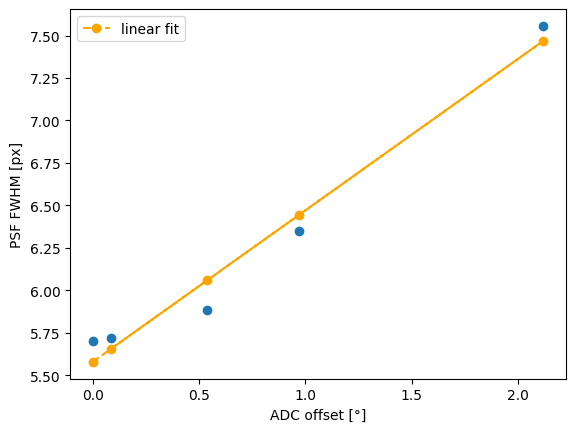

In [200]:
#looking at the linear region, let's make a conversion to physical dispersion units
lin_adc_angles = np.array([0,2.12,0.97,0.54,0.086])
lin_ys = np.array([y1,y3,y5,y6,y7])

m,b = np.polyfit(lin_adc_angles,lin_ys,deg=1)

plt.figure()
plt.scatter(lin_adc_angles,lin_ys)
plt.plot(lin_adc_angles,m*lin_adc_angles+b,'--o',label='linear fit',color='orange')
plt.xlabel('ADC offset [°]')
plt.ylabel('PSF FWHM [px]')
plt.legend()
plt.show()

In [204]:
print(f'slope: {m} pixels/degree of offset')
mas = m * 6
print(f'slope: {mas} mas/degree of offset')
#assuming our bandpass is from 450-1100 nm (0.65 um)
mas_um = mas / 0.6
print(f'slope: {mas_um} mas/um/degree of offset')

slope: 1.571727546493059 pixels/degree of offset
slope: 9.430365278958353 mas/degree of offset
slope: 15.717275464930589 mas/um/degree of offset
